In [14]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

_results = Path("../results")
INGEST_BENCHMARK    = _results / "sweep_20261012-162458/10M_ingest/benchmark_1_ingest_polars_20261012-162506_runs.csv"
TRANSFORM_BENCHMARK = _results / "sweep_20261012-162458/10M_transform/benchmark_2_transform_polars_20261012-162617_runs.csv"
AGG_BENCHMARK       = _results / "sweep_20261012-162458/10M_aggregate/benchmark_3_aggregate_polars_20261012-162646_runs.csv"

In [15]:
ingest_df = pd.read_csv(INGEST_BENCHMARK)
transform_df = pd.read_csv(TRANSFORM_BENCHMARK)
aggregate_df = pd.read_csv(AGG_BENCHMARK)
ingest_df["framework"] = ingest_df["framework"].str.replace(" (local[*])", "", regex=False)
transform_df["framework"] = transform_df["framework"].str.replace(" (local[*])", "", regex=False)
aggregate_df["framework"] = aggregate_df["framework"].str.replace(" (local[*])", "", regex=False)

ingest_df
#transform_df
#aggregate_df


,phase,repeat,position,framework,elapsed_s,mem_delta_mb,rows_out
0,warmup,1,1,Polars,2.6942,708.0,10000000
1,timed,1,1,Polars,0.1748,735.9,10000000
2,timed,2,1,Polars,0.1463,729.4,10000000
3,timed,3,1,Polars,0.1448,612.4,10000000


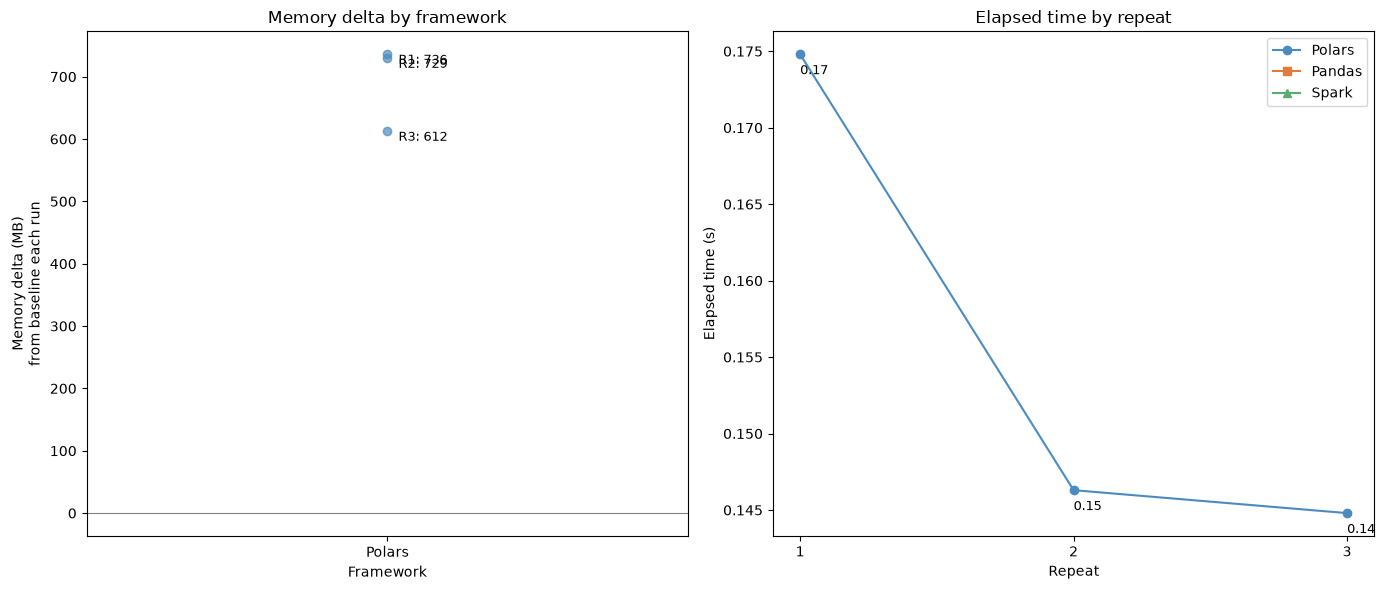

In [16]:
frameworks = ["Polars", "Pandas", "Spark"]
colors     = {"Polars": "#4C8BBF", "Pandas": "#E07B39", "Spark": "#5BAD6F"}
markers    = {"Polars": "o",       "Pandas": "s",        "Spark": "^"}

timed = ingest_df[ingest_df["phase"] == "timed"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: memory delta by framework
for fw in frameworks:
    sub = timed[timed["framework"] == fw]
    axes[0].scatter(sub["framework"], sub["mem_delta_mb"],
                    color=colors[fw], marker=markers[fw], alpha=0.7, label=fw)
    for _, r in sub.iterrows():
        axes[0].annotate(f"R{r['repeat']}: {r['mem_delta_mb']:.0f}",
                     (r["framework"], r["mem_delta_mb"]),
                     textcoords="offset points", xytext=(8, 0),
                     va="top", fontsize=9)

axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_title("Memory delta by framework")
axes[0].set_xlabel("Framework")
axes[0].set_ylabel("Memory delta (MB)\nfrom baseline each run")

# Plot 2: elapsed time by repeat, one line per framework
for fw in frameworks:
    sub = timed[timed["framework"] == fw].sort_values("elapsed_s")
    axes[1].plot(sub["repeat"], sub["elapsed_s"],
                 color=colors[fw], marker=markers[fw], label=fw)
    for _, r in sub.iterrows():
        axes[1].annotate(f"{r['elapsed_s']:.2f}",
                     (r["repeat"], r["elapsed_s"]), fontsize=9,
                     textcoords="offset points", xytext=(0, -12),
                     va="center")

axes[1].set_title("Elapsed time by repeat")
axes[1].set_xlabel("Repeat")
axes[1].set_ylabel("Elapsed time (s)")
axes[1].set_xticks([1, 2, 3])
axes[1].legend()

plt.tight_layout()
plt.show()